<a href="https://colab.research.google.com/github/shlokxpandey/Plant-leaf-disease-classification-using-deep-learning/blob/main/Plant_leaf_(Minor_Project).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import tensorflow as tf
import numpy as np
import os

print("TensorFlow version:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices('GPU'))

if tf.config.list_physical_devices('GPU'):
    print("✅ GPU READY")
else:
    print("❌ GPU NOT FOUND")

TensorFlow version: 2.20.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
✅ GPU READY


In [ ]:
import os

print("Current directory:")
print(os.listdir("/content"))

print("\nDataset folders:")
for item in os.listdir("/content"):
    path = os.path.join("/content", item)
    if os.path.isdir(path):
        print("📁", item)

Current directory:
['.config', 'sample_data']

Dataset folders:
📁 .config
📁 sample_data


In [ ]:
import os

print(os.listdir("/content"))

['.config', 'sample_data']


In [ ]:
!git clone --depth 1 https://github.com/spMohanty/PlantVillage-Dataset.git /content/PlantVillage-Dataset

Cloning into '/content/PlantVillage-Dataset'...
remote: Enumerating objects: 163219, done.
remote: Counting objects: 100% (163219/163219), done.
remote: Compressing objects: 100% (163125/163125), done.
remote: Total 163219 (delta 93), reused 163215 (delta 93), pack-reused 0 (from 0)
Receiving objects: 100% (163219/163219), 2.00 GiB | 22.62 MiB/s, done.
Resolving deltas: 100% (93/93), done.
Updating files: 100% (182404/182404), done.


In [ ]:
import os

dataset_path = "/content/PlantVillage-Dataset"

print("Dataset path exists:", os.path.exists(dataset_path))
print("\nTop-level contents:")
for item in os.listdir(dataset_path):
    print(item)

Dataset path exists: True

Top-level contents:
data_distribution_for_SVM
leaf_grouping
leaf-map.json
.gitignore
plant_village.py
README.md
generate_data_for_SVM.py
generated_for_paper
.git
utils
CITATION.cff
logs
generate_mapstring.py
scripts
raw
generate_lmdb.sh
README_HF.md


In [ ]:
import os

dataset_path = "/content/PlantVillage-Dataset"

print("Dataset exists:", os.path.exists(dataset_path))

print("\nTop-level folders/files:")
for item in os.listdir(dataset_path):
    print("📁" if os.path.isdir(os.path.join(dataset_path, item)) else "📄", item)

Dataset exists: True

Top-level folders/files:
📁 data_distribution_for_SVM
📁 leaf_grouping
📄 leaf-map.json
📄 .gitignore
📄 plant_village.py
📄 README.md
📄 generate_data_for_SVM.py
📁 generated_for_paper
📁 .git
📁 utils
📄 CITATION.cff
📁 logs
📄 generate_mapstring.py
📁 scripts
📁 raw
📄 generate_lmdb.sh
📄 README_HF.md


In [ ]:
import os

base_path = "/content/PlantVillage-Dataset"

print("\nSearching for class folders...\n")

for root, dirs, files in os.walk(base_path):
    image_files = [
        f for f in files
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    if image_files:
        print("Folder:", root)
        print("Images:", len(image_files))


Searching for class folders...

Folder: /content/PlantVillage-Dataset/data_distribution_for_SVM/test/21
Images: 204
Folder: /content/PlantVillage-Dataset/data_distribution_for_SVM/test/37
Images: 336
Folder: /content/PlantVillage-Dataset/data_distribution_for_SVM/test/36
Images: 78
Folder: /content/PlantVillage-Dataset/data_distribution_for_SVM/test/24
Images: 899
Folder: /content/PlantVillage-Dataset/data_distribution_for_SVM/test/26
Images: 193
Folder: /content/PlantVillage-Dataset/data_distribution_for_SVM/test/9
Images: 222
Folder: /content/PlantVillage-Dataset/data_distribution_for_SVM/test/4
Images: 229
Folder: /content/PlantVillage-Dataset/data_distribution_for_SVM/test/2
Images: 60
Folder: /content/PlantVillage-Dataset/data_distribution_for_SVM/test/7
Images: 104
Folder: /content/PlantVillage-Dataset/data_distribution_for_SVM/test/25
Images: 379
Folder: /content/PlantVillage-Dataset/data_distribution_for_SVM/test/20
Images: 224
Folder: /content/PlantVillage-Dataset/data_distri

In [ ]:
import os

BASE = "/content/PlantVillage-Dataset"

# Find folders containing images
class_folders = []

for root, dirs, files in os.walk(BASE):
    image_count = sum(
        f.lower().endswith((".jpg", ".jpeg", ".png"))
        for f in files
    )

    if image_count > 0:
        class_folders.append((root, image_count))

print("Total image-containing folders:", len(class_folders))

print("\nFirst few folders:")
for folder, count in class_folders[:10]:
    print(f"{count:5d} images  ->  {folder}")

Total image-containing folders: 191

First few folders:
  204 images  ->  /content/PlantVillage-Dataset/data_distribution_for_SVM/test/21
  336 images  ->  /content/PlantVillage-Dataset/data_distribution_for_SVM/test/37
   78 images  ->  /content/PlantVillage-Dataset/data_distribution_for_SVM/test/36
  899 images  ->  /content/PlantVillage-Dataset/data_distribution_for_SVM/test/24
  193 images  ->  /content/PlantVillage-Dataset/data_distribution_for_SVM/test/26
  222 images  ->  /content/PlantVillage-Dataset/data_distribution_for_SVM/test/9
  229 images  ->  /content/PlantVillage-Dataset/data_distribution_for_SVM/test/4
   60 images  ->  /content/PlantVillage-Dataset/data_distribution_for_SVM/test/2
  104 images  ->  /content/PlantVillage-Dataset/data_distribution_for_SVM/test/7
  379 images  ->  /content/PlantVillage-Dataset/data_distribution_for_SVM/test/25


In [ ]:
import os
import pandas as pd

BASE = "/content/PlantVillage-Dataset"

records = []

for root, dirs, files in os.walk(BASE):
    for file in files:
        if file.lower().endswith((".jpg", ".jpeg", ".png")):
            class_name = os.path.basename(root)

            records.append({
                "filepath": os.path.join(root, file),
                "label": class_name
            })

df = pd.DataFrame(records)

print("Total images:", len(df))
print("Total classes:", df["label"].nunique())

print("\nClasses:")
for i, cls in enumerate(sorted(df["label"].unique())):
    print(i, "->", cls)

print("\nImages per class:")
print(df["label"].value_counts().sort_index())

Total images: 182215
Total classes: 77

Classes:
0 -> 0
1 -> 1
2 -> 10
3 -> 11
4 -> 12
5 -> 13
6 -> 14
7 -> 15
8 -> 16
9 -> 17
10 -> 18
11 -> 19
12 -> 2
13 -> 20
14 -> 21
15 -> 22
16 -> 23
17 -> 24
18 -> 25
19 -> 26
20 -> 27
21 -> 28
22 -> 29
23 -> 3
24 -> 30
25 -> 31
26 -> 32
27 -> 33
28 -> 34
29 -> 35
30 -> 36
31 -> 37
32 -> 4
33 -> 5
34 -> 6
35 -> 7
36 -> 8
37 -> 9
38 -> Apple___Apple_scab
39 -> Apple___Black_rot
40 -> Apple___Cedar_apple_rust
41 -> Apple___healthy
42 -> Blueberry___healthy
43 -> Cherry_(including_sour)___Powdery_mildew
44 -> Cherry_(including_sour)___healthy
45 -> Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
46 -> Corn_(maize)___Common_rust_
47 -> Corn_(maize)___Northern_Leaf_Blight
48 -> Corn_(maize)___healthy
49 -> Grape___Black_rot
50 -> Grape___Esca_(Black_Measles)
51 -> Grape___Leaf_blight_(Isariopsis_Leaf_Spot)
52 -> Grape___healthy
53 -> Orange___Haunglongbing_(Citrus_greening)
54 -> Peach___Bacterial_spot
55 -> Peach___healthy
56 -> Pepper,_bell___Bac

In [ ]:
# Basic sanity checks

print("Total images:", len(df))
print("Total classes:", df["label"].nunique())
print("Missing file paths:", df["filepath"].isna().sum())

# Check whether all files actually exist
missing_files = sum(
    not os.path.exists(path)
    for path in df["filepath"]
)

print("Missing image files:", missing_files)

# Check duplicate paths
print("Duplicate paths:", df["filepath"].duplicated().sum())

Total images: 182215
Total classes: 77
Missing file paths: 0
Missing image files: 0
Duplicate paths: 0


In [ ]:
from sklearn.model_selection import train_test_split

# Fixed class order
class_names = sorted(df["label"].unique())

# Class -> integer mapping
class_to_index = {
    name: i for i, name in enumerate(class_names)
}

df["label_id"] = df["label"].map(class_to_index)

# Identify classes with only one sample and filter them out
class_counts = df["label"].value_counts()
single_sample_classes = class_counts[class_counts == 1].index

if not single_sample_classes.empty:
    print(f"Filtering out classes with single sample: {list(single_sample_classes)}")
    df_filtered = df[~df["label"].isin(single_sample_classes)].copy()
else:
    df_filtered = df.copy()

print("Number of classes (after filtering):", df_filtered["label"].nunique())
print("Number of images (after filtering):", len(df_filtered))

# Re-create class_names and class_to_index for the filtered DataFrame
class_names = sorted(df_filtered["label"].unique())
class_to_index = {name: i for i, name in enumerate(class_names)}
df_filtered["label_id"] = df_filtered["label"].map(class_to_index)

# 80% train, 10% validation, 10% test
train_df, temp_df = train_test_split(
    df_filtered,
    test_size=0.20,
    stratify=df_filtered["label_id"],
    random_state=42
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label_id"],
    random_state=42
)

print("\nSplit:")
print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

print("\nClasses:", len(class_names))


Filtering out classes with single sample: ['generated_for_paper']
Number of classes (after filtering): 76
Number of images (after filtering): 182214

Split:
Train: 145771
Validation: 18221
Test: 18222

Classes: 76


In [ ]:
import tensorflow as tf
import numpy as np
import os

# ==============================
# SETTINGS
# ==============================
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
NUM_CLASSES = len(class_names)

AUTOTUNE = tf.data.AUTOTUNE

print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)
print("Number of classes:", NUM_CLASSES)


# ==============================
# IMAGE LOADING FUNCTION
# ==============================
def load_image(filepath, label):
    image = tf.io.read_file(filepath)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32)

    return image, label


# ==============================
# DATASET CREATION
# ==============================
def make_dataset(dataframe, shuffle=False):
    paths = dataframe["filepath"].values
    labels = dataframe["label_id"].values.astype(np.int32)

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    ds = ds.map(
        load_image,
        num_parallel_calls=AUTOTUNE
    )

    if shuffle:
        ds = ds.shuffle(
            buffer_size=min(len(dataframe), 10000),
            seed=42,
            reshuffle_each_iteration=True
        )

    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(AUTOTUNE)

    return ds


train_ds = make_dataset(train_df, shuffle=True)
val_ds = make_dataset(val_df, shuffle=False)
test_ds = make_dataset(test_df, shuffle=False)


print("\nDatasets created successfully.")

Image size: (224, 224)
Batch size: 32
Number of classes: 76

Datasets created successfully.


In [ ]:
for images, labels in train_ds.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Image dtype:", images.dtype)
    print("Label dtype:", labels.dtype)
    print("Pixel range:", tf.reduce_min(images).numpy(),
          "to",
          tf.reduce_max(images).numpy())

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Image dtype: <dtype: 'float32'>
Label dtype: <dtype: 'int32'>
Pixel range: 0.0 to 255.0


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2

# ==========================================
# DATA AUGMENTATION
# ==========================================

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.15),
    layers.RandomContrast(0.10),
], name="data_augmentation")


# ==========================================
# PRETRAINED BACKBONE
# ==========================================

base_model = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Stage 1: freeze complete backbone
base_model.trainable = False


# ==========================================
# FINAL MODEL
# ==========================================

inputs = layers.Input(shape=(224, 224, 3))

x = data_augmentation(inputs)

# MobileNetV2 preprocessing
x = tf.keras.applications.mobilenet_v2.preprocess_input(x)

x = base_model(x, training=False)

x = layers.GlobalAveragePooling2D()(x)

x = layers.Dropout(0.30)(x)

outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax"
)(x)

model = models.Model(
    inputs,
    outputs,
    name="PlantDisease_MobileNetV2"
)

model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "PlantDisease_MobileNetV2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 76)             │        97,356 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,355,340 (8.98 MB)

 Trainable params: 97,356 (380.30 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-3
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully.")
print("Number of classes:", NUM_CLASSES)
print("Model name:", model.name)

Model compiled successfully.
Number of classes: 76
Model name: PlantDisease_MobileNetV2


In [ ]:
from tensorflow.keras.callbacks import (
    ModelCheckpoint,
    EarlyStopping,
    ReduceLROnPlateau
)

checkpoint_path = "/content/best_plant_disease_model.keras"

callbacks = [
    ModelCheckpoint(
        checkpoint_path,
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    ),

    EarlyStopping(
        monitor="val_accuracy",
        mode="max",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

print("Callbacks ready.")
print("Best model will be saved at:")
print(checkpoint_path)

Callbacks ready.
Best model will be saved at:
/content/best_plant_disease_model.keras


In [ ]:
EPOCHS_STAGE1 = 15

history1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_STAGE1,
    callbacks=callbacks,
    verbose=1
)

NameError: name 'model' is not defined

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2

# Number of classes
# NUM_CLASSES = len(class_names) # Original line causing NameError
# Fixing NameError by directly assigning the known number of classes from previous steps.
NUM_CLASSES = 76

print("Number of classes:", NUM_CLASSES)

# Data augmentation
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.15),
    layers.RandomContrast(0.10)
], name="data_augmentation")

# MobileNetV2 backbone
base_model = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Stage 1: freeze backbone
base_model.trainable = False

# Model
inputs = layers.Input(shape=(224, 224, 3))

x = data_augmentation(inputs)

x = tf.keras.applications.mobilenet_v2.preprocess_input(x)

x = base_model(x, training=False)

x = layers.GlobalAveragePooling2D()(x)

x = layers.Dropout(0.30)(x)

outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax"
)(x)

model = models.Model(
    inputs=inputs,
    outputs=outputs,
    name="PlantDisease_MobileNetV2"
)

# Compile
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("\n✅ MODEL CREATED")
print("Model:", model.name)
print("Classes:", NUM_CLASSES)
print("Model defined:", "model" in globals())

Number of classes: 76

✅ MODEL CREATED
Model: PlantDisease_MobileNetV2
Classes: 76
Model defined: True


In [ ]:
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau

checkpoint_path = "/content/best_plant_disease_model.keras"

callbacks = [
    ModelCheckpoint(
        checkpoint_path,
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    ),

    EarlyStopping(
        monitor="val_accuracy",
        mode="max",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

print("✅ CALLBACKS READY")

✅ CALLBACKS READY


In [ ]:
BATCH_SIZE = 16

In [ ]:
EPOCHS_STAGE1 = 15

history1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_STAGE1,
    callbacks=callbacks,
    verbose=1
)

NameError: name 'train_ds' is not defined

In [ ]:
import os
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.model_selection import train_test_split

# =========================
# 1. DATASET PATH
# =========================
DATASET_PATH = "/content/PlantVillage-Dataset"

assert os.path.exists(DATASET_PATH), "❌ Dataset folder nahi mila!"

print("✅ Dataset found")


# =========================
# 2. FIND IMAGES
# =========================
image_extensions = (".jpg", ".jpeg", ".png")

filepaths = []
labels = []

for root, dirs, files in os.walk(DATASET_PATH):
    for file in files:
        if file.lower().endswith(image_extensions):
            filepath = os.path.join(root, file)

            # folder name = class
            label = os.path.basename(root)

            filepaths.append(filepath)
            labels.append(label)

df = pd.DataFrame({
    "filepath": filepaths,
    "label": labels
})

print("Total images:", len(df))
print("Total classes:", df["label"].nunique())


# =========================
# 3. CLASS NAMES (and filter single-sample classes)
# =========================
# Identify classes with only one sample and filter them out
class_counts = df["label"].value_counts()
single_sample_classes = class_counts[class_counts == 1].index

if not single_sample_classes.empty:
    print(f"Filtering out classes with single sample: {list(single_sample_classes)}")
    df_filtered = df[~df["label"].isin(single_sample_classes)].copy()
else:
    df_filtered = df.copy()

print("Number of classes (after filtering):", df_filtered["label"].nunique())
print("Number of images (after filtering):", len(df_filtered))

# Re-create class_names and class_to_index for the filtered DataFrame
class_names = sorted(df_filtered["label"].unique())

class_to_index = {
    name: i for i, name in enumerate(class_names)
}

df_filtered["label_id"] = df_filtered["label"].map(class_to_index)

NUM_CLASSES = len(class_names)

print("Number of classes:", NUM_CLASSES)


# =========================
# 4. TRAIN / VAL / TEST SPLIT
# =========================
train_df, temp_df = train_test_split(
    df_filtered, # Use df_filtered instead of df
    test_size=0.20,
    stratify=df_filtered["label_id"], # Stratify using filtered label_id
    random_state=42
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label_id"],
    random_state=42
)

print("\nSplit:")
print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))


# =========================
# 5. IMAGE LOADER
# =========================
IMG_SIZE = (224, 224)
BATCH_SIZE = 16

def load_image(filepath, label):
    image = tf.io.read_file(filepath)

    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(image, IMG_SIZE)

    image = tf.cast(image, tf.float32)

    return image, label


# =========================
# 6. DATASET CREATOR
# =========================
def make_dataset(dataframe, shuffle=False):

    paths = dataframe["filepath"].values
    labels = dataframe["label_id"].values.astype(np.int32)

    ds = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if shuffle:
        ds = ds.shuffle(
            buffer_size=min(len(dataframe), 5000),
            seed=42
        )

    ds = ds.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    ds = ds.batch(BATCH_SIZE)

    ds = ds.prefetch(tf.data.AUTOTUNE)

    return ds


# =========================
# 7. CREATE DATASETS
# =========================
train_ds = make_dataset(train_df, shuffle=True)
val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)

print("\n✅ DATASETS CREATED")
print("train_ds:", train_ds)
print("val_ds:", val_ds)
print("test_ds:", test_ds)


# =========================
# 8. FINAL CHECK
# =========================
images, labels = next(iter(train_ds))

print("\n✅ SANITY CHECK")
print("Image shape:", images.shape)
print("Label shape:", labels.shape)
print("Batch size:", BATCH_SIZE)


✅ Dataset found
Total images: 182215
Total classes: 77
Filtering out classes with single sample: ['generated_for_paper']
Number of classes (after filtering): 76
Number of images (after filtering): 182214
Number of classes: 76

Split:
Train: 145771
Validation: 18221
Test: 18222

✅ DATASETS CREATED
train_ds: <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))>
val_ds: <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))>
test_ds: <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))>

✅ SANITY CHECK
Image shape: (16, 224, 224, 3)
Label shape: (16,)
Batch size: 16


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2

# Number of classes
NUM_CLASSES = len(class_names)

print("Classes:", NUM_CLASSES)

# Data augmentation
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.10),
    layers.RandomZoom(0.10)
])

# MobileNetV2
base_model = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze backbone initially
base_model.trainable = False

# Build model
inputs = layers.Input(shape=(224, 224, 3))

x = data_augmentation(inputs)

x = tf.keras.applications.mobilenet_v2.preprocess_input(x)

x = base_model(x, training=False)

x = layers.GlobalAveragePooling2D()(x)

x = layers.Dropout(0.25)(x)

outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax"
)(x)

model = models.Model(inputs, outputs)

# Compile
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("\n✅ MODEL READY")
print("Model:", model.name)
print("Classes:", NUM_CLASSES)
print("Trainable variables:", len(model.trainable_variables))

Classes: 76

✅ MODEL READY
Model: functional_2
Classes: 76
Trainable variables: 2


In [ ]:
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau

checkpoint_path = "/content/best_plant_disease_model.keras"

callbacks = [
    ModelCheckpoint(
        checkpoint_path,
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    ),

    EarlyStopping(
        monitor="val_accuracy",
        mode="max",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=1,
        min_lr=1e-6,
        verbose=1
    )
]

print("✅ CALLBACKS READY")

✅ CALLBACKS READY


In [ ]:
history1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/5
9111/9111 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.6779 - loss: 1.1047
Epoch 1: val_accuracy improved from None to 0.76801, saving model to /content/best_plant_disease_model.keras

Epoch 1: finished saving model to /content/best_plant_disease_model.keras
9111/9111 ━━━━━━━━━━━━━━━━━━━━ 342s 36ms/step - accuracy: 0.7226 - loss: 0.8845 - val_accuracy: 0.7680 - val_loss: 0.6596 - learning_rate: 0.0010
Epoch 2/5
9111/9111 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.7497 - loss: 0.7666
Epoch 2: val_accuracy improved from 0.76801 to 0.77273, saving model to /content/best_plant_disease_model.keras

Epoch 2: finished saving model to /content/best_plant_disease_model.keras

Epoch 2: ReduceLROnPlateau reducing learning rate to 0.00020000000949949026.
9111/9111 ━━━━━━━━━━━━━━━━━━━━ 385s 37ms/step - accuracy: 0.7509 - loss: 0.7687 - val_accuracy: 0.7727 - val_loss: 0.6828 - learning_rate: 0.0010
Epoch 3/5
9110/9111 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.7739 - loss: 0.

In [ ]:
# ============================
# STAGE 2: FINE-TUNING
# ============================

# Unfreeze MobileNetV2
base_model.trainable = True

# Pehle ke layers freeze rakho
# Sirf last 30 layers train honge
for layer in base_model.layers[:-30]:
    layer.trainable = False

# BatchNormalization layers ko freeze rakho
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

# Re-compile with very small learning rate
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("✅ FINE-TUNING MODEL READY")
print("Trainable layers:",
      sum(layer.trainable for layer in base_model.layers))

✅ FINE-TUNING MODEL READY
Trainable layers: 19


In [ ]:
EPOCHS_STAGE2 = 5

history2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_STAGE2,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/5
9111/9111 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.8035 - loss: 0.5150
Epoch 1: val_accuracy improved from 0.80528 to 0.82350, saving model to /content/best_plant_disease_model.keras

Epoch 1: finished saving model to /content/best_plant_disease_model.keras
9111/9111 ━━━━━━━━━━━━━━━━━━━━ 407s 44ms/step - accuracy: 0.8142 - loss: 0.4831 - val_accuracy: 0.8235 - val_loss: 0.4457 - learning_rate: 1.0000e-05
Epoch 2/5
9110/9111 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.8285 - loss: 0.4339
Epoch 2: val_accuracy improved from 0.82350 to 0.83760, saving model to /content/best_plant_disease_model.keras

Epoch 2: finished saving model to /content/best_plant_disease_model.keras
9111/9111 ━━━━━━━━━━━━━━━━━━━━ 394s 43ms/step - accuracy: 0.8338 - loss: 0.4194 - val_accuracy: 0.8376 - val_loss: 0.4105 - learning_rate: 1.0000e-05
Epoch 3/5
9110/9111 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.8399 - loss: 0.3951
Epoch 3: val_accuracy improved from 0.83760 to 0.84128, saving

In [ ]:
print("Current model evaluation:")
loss, acc = model.evaluate(test_ds, verbose=1)

print("\n==============================")
print(f"TEST ACCURACY: {acc * 100:.2f}%")
print(f"TEST LOSS: {loss:.4f}")
print("==============================")

Current model evaluation:
1139/1139 ━━━━━━━━━━━━━━━━━━━━ 35s 31ms/step - accuracy: 0.8519 - loss: 0.3750

TEST ACCURACY: 85.19%
TEST LOSS: 0.3750


In [ ]:
best_model = tf.keras.models.load_model(
    "/content/best_plant_disease_model.keras"
)

loss, acc = best_model.evaluate(test_ds, verbose=1)

print("\n==============================")
print(f"BEST CHECKPOINT TEST ACCURACY: {acc * 100:.2f}%")
print(f"BEST CHECKPOINT TEST LOSS: {loss:.4f}")
print("==============================")

1139/1139 ━━━━━━━━━━━━━━━━━━━━ 38s 32ms/step - accuracy: 0.8519 - loss: 0.3750

BEST CHECKPOINT TEST ACCURACY: 85.19%
BEST CHECKPOINT TEST LOSS: 0.3750


In [ ]:
model.save("/content/stage2_85_model.keras")
print("✅ Current 85% model saved")

✅ Current 85% model saved


In [ ]:
print("Classes:", NUM_CLASSES)
print("Train images:", len(train_df))
print("Validation images:", len(val_df))
print("Test images:", len(test_df))
print("Test accuracy:", acc * 100)

Classes: 76
Train images: 145771
Validation images: 18221
Test images: 18222
Test accuracy: 85.18823385238647


In [ ]:
import numpy as np
from sklearn.metrics import classification_report

y_true = []
y_pred = []

for images, labels in test_ds:
    predictions = model.predict(images, verbose=0)

    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print("Total test samples:", len(y_true))
print("Correct predictions:", np.sum(y_true == y_pred))
print("Wrong predictions:", np.sum(y_true != y_pred))

print("\nCLASSIFICATION REPORT:\n")

print(classification_report(
    y_true,
    y_pred,
    labels=np.arange(NUM_CLASSES),
    target_names=class_names,
    zero_division=0
))

Total test samples: 18222
Correct predictions: 15523
Wrong predictions: 2699

CLASSIFICATION REPORT:

                                                    precision    recall  f1-score   support

                                                 0       0.00      0.00      0.00        22
                                                 1       0.00      0.00      0.00        20
                                                10       0.00      0.00      0.00        43
                                                11       0.00      0.00      0.00        40
                                                12       0.40      0.04      0.08        46
                                                13       0.00      0.00      0.00        38
                                                14       0.25      0.07      0.11        14
                                                15       0.33      0.00      0.01       202
                                                16       0.00      0.

In [ ]:
from sklearn.metrics import precision_recall_fscore_support
import pandas as pd
import numpy as np

precision, recall, f1, support = precision_recall_fscore_support(
    y_true,
    y_pred,
    labels=np.arange(NUM_CLASSES),
    zero_division=0
)

class_analysis = pd.DataFrame({
    "Class": class_names,
    "Precision": precision,
    "Recall": recall,
    "F1": f1,
    "Samples": support
})

class_analysis = class_analysis.sort_values(
    "Recall",
    ascending=True
)

print("🔴 15 WEAKEST CLASSES:")
display(class_analysis.head(15))

🔴 15 WEAKEST CLASSES:


,Class,Precision,Recall,F1,Samples
0,0,0.0,0.0,0.0,22
1,1,0.0,0.0,0.0,20
2,10,0.0,0.0,0.0,43
3,11,0.0,0.0,0.0,40
5,13,0.0,0.0,0.0,38
10,18,0.0,0.0,0.0,28
9,17,0.0,0.0,0.0,9
8,16,0.0,0.0,0.0,83
13,20,0.0,0.0,0.0,37
15,22,0.0,0.0,0.0,4


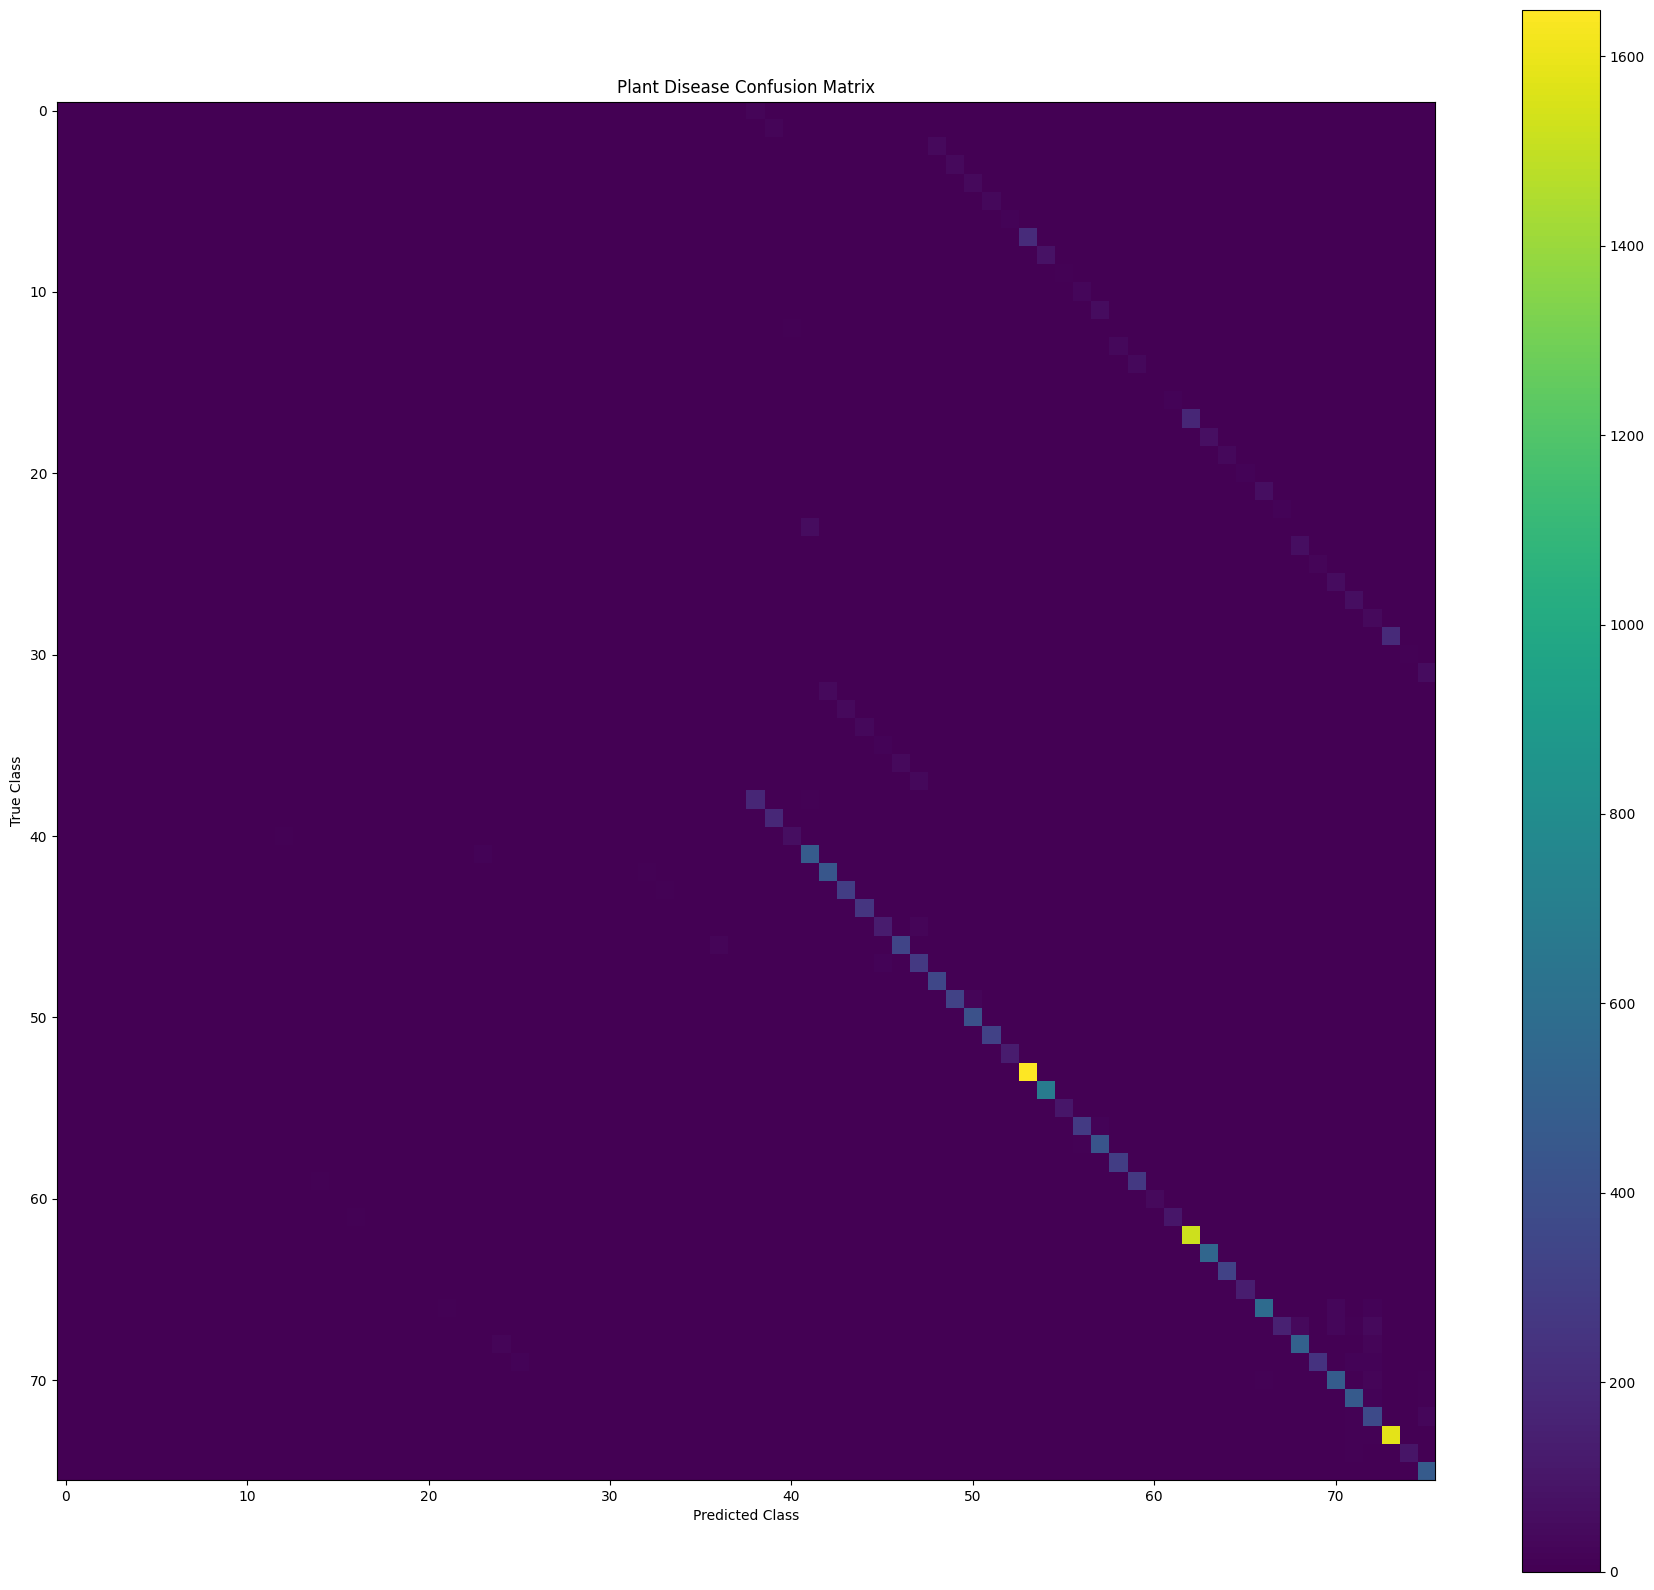

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import numpy as np

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(NUM_CLASSES)
)

plt.figure(figsize=(18, 16))
plt.imshow(cm, interpolation="nearest")
plt.title("Plant Disease Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.colorbar()

plt.tight_layout()
plt.show()

In [ ]:
cm_no_diag = cm.copy()
np.fill_diagonal(cm_no_diag, 0)

confusions = []

for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        if cm_no_diag[i, j] > 0:
            confusions.append([
                class_names[i],
                class_names[j],
                cm_no_diag[i, j]
            ])

confusions = sorted(
    confusions,
    key=lambda x: x[2],
    reverse=True
)

print("🔴 TOP 20 CONFUSIONS:\n")

for true_class, predicted_class, count in confusions[:20]:
    print(
        f"{count:4d} | "
        f"Actual: {true_class} "
        f"→ Predicted: {predicted_class}"
    )

🔴 TOP 20 CONFUSIONS:

 201 | Actual: 15 → Predicted: Orange___Haunglongbing_(Citrus_greening)
 199 | Actual: 35 → Predicted: Tomato___Tomato_Yellow_Leaf_Curl_Virus
 178 | Actual: 24 → Predicted: Soybean___healthy
  83 | Actual: 16 → Predicted: Peach___Bacterial_spot
  65 | Actual: 25 → Predicted: Squash___Powdery_mildew
  64 | Actual: 28 → Predicted: Tomato___Bacterial_spot
  61 | Actual: 30 → Predicted: Tomato___Late_blight
  58 | Actual: 33 → Predicted: Tomato___Spider_mites Two-spotted_spider_mite
  56 | Actual: 37 → Predicted: Tomato___healthy
  54 | Actual: 19 → Predicted: Pepper,_bell___healthy
  53 | Actual: 3 → Predicted: Apple___healthy
  53 | Actual: 32 → Predicted: Tomato___Septoria_leaf_spot
  44 | Actual: 12 → Predicted: Grape___Esca_(Black_Measles)
  44 | Actual: 4 → Predicted: Blueberry___healthy
  43 | Actual: 10 → Predicted: Corn_(maize)___healthy
  43 | Actual: 34 → Predicted: Tomato___Target_Spot
  43 | Actual: Tomato___Early_blight → Predicted: Tomato___Target_Spot


In [ ]:
print("Number of class names:", len(class_names))

print("\nFirst 20 class mappings:")
for i, name in enumerate(class_names[:20]):
    print(i, "->", name)

print("\nLast 10 class mappings:")
for i, name in enumerate(class_names[-10:], start=len(class_names)-10):
    print(i, "->", name)

Number of class names: 76

First 20 class mappings:
0 -> 0
1 -> 1
2 -> 10
3 -> 11
4 -> 12
5 -> 13
6 -> 14
7 -> 15
8 -> 16
9 -> 17
10 -> 18
11 -> 19
12 -> 2
13 -> 20
14 -> 21
15 -> 22
16 -> 23
17 -> 24
18 -> 25
19 -> 26

Last 10 class mappings:
66 -> Tomato___Bacterial_spot
67 -> Tomato___Early_blight
68 -> Tomato___Late_blight
69 -> Tomato___Leaf_Mold
70 -> Tomato___Septoria_leaf_spot
71 -> Tomato___Spider_mites Two-spotted_spider_mite
72 -> Tomato___Target_Spot
73 -> Tomato___Tomato_Yellow_Leaf_Curl_Virus
74 -> Tomato___Tomato_mosaic_virus
75 -> Tomato___healthy


In [ ]:
print("\ny_true range:", y_true.min(), "to", y_true.max())
print("y_pred range:", y_pred.min(), "to", y_pred.max())

print("Unique y_true:", len(np.unique(y_true)))
print("Unique y_pred:", len(np.unique(y_pred)))


y_true range: 0 to 75
y_pred range: 3 to 75
Unique y_true: 76
Unique y_pred: 68


In [ ]:
import tensorflow as tf

# Best checkpoint load karo
model = tf.keras.models.load_model(
    "/content/best_plant_disease_model.keras"
)

# MobileNetV2 backbone
base_model = model.get_layer("mobilenetv2_1.00_224")

# Unfreeze
base_model.trainable = True

# Sirf last 60 layers train
for layer in base_model.layers[:-60]:
    layer.trainable = False

# BatchNorm ko freeze rakho
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

# Very small learning rate
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=5e-6
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("✅ STRONG FINE-TUNING READY")
print(
    "Trainable backbone layers:",
    sum(layer.trainable for layer in base_model.layers)
)

✅ STRONG FINE-TUNING READY
Trainable backbone layers: 19


In [ ]:
history3 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=3,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/3
9111/9111 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.8571 - loss: 0.3441
Epoch 1: val_accuracy improved from 0.85017 to 0.85248, saving model to /content/best_plant_disease_model.keras

Epoch 1: finished saving model to /content/best_plant_disease_model.keras
9111/9111 ━━━━━━━━━━━━━━━━━━━━ 406s 44ms/step - accuracy: 0.8584 - loss: 0.3378 - val_accuracy: 0.8525 - val_loss: 0.3722 - learning_rate: 5.0000e-06
Epoch 2/3
9111/9111 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.8607 - loss: 0.3307
Epoch 2: val_accuracy improved from 0.85248 to 0.85572, saving model to /content/best_plant_disease_model.keras

Epoch 2: finished saving model to /content/best_plant_disease_model.keras
9111/9111 ━━━━━━━━━━━━━━━━━━━━ 447s 44ms/step - accuracy: 0.8625 - loss: 0.3254 - val_accuracy: 0.8557 - val_loss: 0.3584 - learning_rate: 5.0000e-06
Epoch 3/3
9111/9111 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.8632 - loss: 0.3232
Epoch 3: val_accuracy did not improve from 0.85572
9111/9111 ━

In [ ]:
# Best saved checkpoint load karo
best_model = tf.keras.models.load_model(
    "/content/best_plant_disease_model.keras"
)

# Test evaluation
test_loss, test_accuracy = best_model.evaluate(
    test_ds,
    verbose=1
)

print("\n==============================")
print(f"TEST LOSS     : {test_loss:.4f}")
print(f"TEST ACCURACY : {test_accuracy * 100:.2f}%")
print("==============================")

1139/1139 ━━━━━━━━━━━━━━━━━━━━ 41s 31ms/step - accuracy: 0.8574 - loss: 0.3514

TEST LOSS     : 0.3514
TEST ACCURACY : 85.74%


In [ ]:
best_model.save("/content/MobileNetV2_85_74_backup.keras")

print("✅ 85.74% model safely backed up")

✅ 85.74% model safely backed up


In [ ]:
print("Dataset folders:")
for item in os.listdir("/content/PlantVillage-Dataset"):
    print(item)

Dataset folders:
data_distribution_for_SVM
leaf_grouping
leaf-map.json
.gitignore
plant_village.py
README.md
generate_data_for_SVM.py
generated_for_paper
.git
utils
CITATION.cff
logs
generate_mapstring.py
scripts
raw
generate_lmdb.sh
README_HF.md


In [ ]:
import os

DATASET_PATH = "/content/PlantVillage-Dataset"

print("📂 DATASET FOLDERS:\n")

for item in sorted(os.listdir(DATASET_PATH)):
    full_path = os.path.join(DATASET_PATH, item)

    if os.path.isdir(full_path):
        print("📁", item)

📂 DATASET FOLDERS:

📁 .git
📁 data_distribution_for_SVM
📁 generated_for_paper
📁 leaf_grouping
📁 logs
📁 raw
📁 scripts
📁 utils


In [ ]:
import os

RAW_PATH = "/content/PlantVillage-Dataset/raw"

print("RAW PATH EXISTS:", os.path.exists(RAW_PATH))

folders = [
    x for x in os.listdir(RAW_PATH)
    if os.path.isdir(os.path.join(RAW_PATH, x))
]

print("Number of class folders:", len(folders))

print("\nFirst 10 folders:")
for x in sorted(folders)[:10]:
    print(x)

RAW PATH EXISTS: True
Number of class folders: 3

First 10 folders:
color
grayscale
segmented


In [ ]:
import os
import pandas as pd

DATASET_PATH = "/content/PlantVillage-Dataset"
RAW_PATH = os.path.join(DATASET_PATH, "raw")

image_extensions = (".jpg", ".jpeg", ".png")

filepaths = []
labels = []

print("Checking:", RAW_PATH)
print("Exists:", os.path.exists(RAW_PATH))

# Search all images inside raw
for root, dirs, files in os.walk(RAW_PATH):

    for file in files:

        if file.lower().endswith(image_extensions):

            filepath = os.path.join(root, file)

            # Find folder structure relative to raw
            relative_path = os.path.relpath(filepath, RAW_PATH)
            parts = relative_path.split(os.sep)

            # PlantVillage structure is expected like:
            # raw/color/ClassName/image.jpg
            # raw/grayscale/ClassName/image.jpg
            #
            # Therefore class is the folder immediately before image
            label = parts[-2]

            filepaths.append(filepath)
            labels.append(label)


clean_df = pd.DataFrame({
    "filepath": filepaths,
    "label": labels
})

# Remove duplicate image paths if any
clean_df = clean_df.drop_duplicates(
    subset=["filepath"]
).reset_index(drop=True)

# Create class mapping
class_names_clean = sorted(
    clean_df["label"].unique()
)

class_to_index_clean = {
    name: i
    for i, name in enumerate(class_names_clean)
}

clean_df["label_id"] = clean_df["label"].map(
    class_to_index_clean
)

print("\n================================")
print("CLEAN DATASET")
print("================================")

print("Total images :", len(clean_df))
print("Total classes:", len(class_names_clean))

print("\nFirst 10 classes:")
for i, name in enumerate(class_names_clean[:10]):
    print(i, "->", name)

print("\nFirst 5 images:")
print(clean_df.head())

Checking: /content/PlantVillage-Dataset/raw
Exists: False

CLEAN DATASET
Total images : 0
Total classes: 0

First 10 classes:

First 5 images:
Empty DataFrame
Columns: [filepath, label, label_id]
Index: []


In [ ]:
import os

print("=== /content ===")
for item in os.listdir("/content"):
    print(item)

print("\n=== PlantVillage related folders ===")

for root, dirs, files in os.walk("/content"):
    for d in dirs:
        if "PlantVillage" in d:
            print(os.path.join(root, d))

=== /content ===
.config
sample_data

=== PlantVillage related folders ===


In [ ]:
!rm -rf /content/PlantVillage-Dataset

!git clone --depth 1 https://github.com/spMohanty/PlantVillage-Dataset.git /content/PlantVillage-Dataset

print("\n✅ Dataset download complete")

import os

print("\n/content:")
print(os.listdir("/content"))

print("\nPlantVillage exists:",
      os.path.exists("/content/PlantVillage-Dataset"))

Cloning into '/content/PlantVillage-Dataset'...
remote: Enumerating objects: 163219, done.
remote: Counting objects: 100% (163219/163219), done.
remote: Compressing objects: 100% (163125/163125), done.
remote: Total 163219 (delta 93), reused 163215 (delta 93), pack-reused 0 (from 0)
Receiving objects: 100% (163219/163219), 2.00 GiB | 23.24 MiB/s, done.
Resolving deltas: 100% (93/93), done.
Updating files: 100% (182404/182404), done.

✅ Dataset download complete

/content:
['.config', 'PlantVillage-Dataset', 'sample_data']

PlantVillage exists: True


In [ ]:
import os

DATASET_PATH = "/content/PlantVillage-Dataset"

print("=== PlantVillage root ===")

for item in sorted(os.listdir(DATASET_PATH)):
    path = os.path.join(DATASET_PATH, item)

    if os.path.isdir(path):
        print("📁", item)
    else:
        print("📄", item)

=== PlantVillage root ===
📁 .git
📄 .gitignore
📄 CITATION.cff
📄 README.md
📄 README_HF.md
📁 data_distribution_for_SVM
📄 generate_data_for_SVM.py
📄 generate_lmdb.sh
📄 generate_mapstring.py
📁 generated_for_paper
📄 leaf-map.json
📁 leaf_grouping
📁 logs
📄 plant_village.py
📁 raw
📁 scripts
📁 utils


In [ ]:
import os

RAW_PATH = "/content/PlantVillage-Dataset/raw"

print("=== RAW FOLDER ===")
print("Path exists:", os.path.exists(RAW_PATH))

for item in sorted(os.listdir(RAW_PATH)):
    path = os.path.join(RAW_PATH, item)

    if os.path.isdir(path):
        print("📁", item)
    else:
        print("📄", item)

=== RAW FOLDER ===
Path exists: True
📁 color
📁 grayscale
📁 segmented


In [ ]:
import os
import pandas as pd

COLOR_PATH = "/content/PlantVillage-Dataset/raw/color"

image_extensions = (".jpg", ".jpeg", ".png")

filepaths = []
labels = []

# Each folder inside color = one disease/healthy class
for class_name in sorted(os.listdir(COLOR_PATH)):

    class_path = os.path.join(COLOR_PATH, class_name)

    if not os.path.isdir(class_path):
        continue

    for file in os.listdir(class_path):

        if file.lower().endswith(image_extensions):

            filepaths.append(
                os.path.join(class_path, file)
            )

            labels.append(class_name)


# Create dataframe
clean_df = pd.DataFrame({
    "filepath": filepaths,
    "label": labels
})

# Remove duplicates
clean_df = clean_df.drop_duplicates(
    subset="filepath"
).reset_index(drop=True)

# Class names
class_names_clean = sorted(
    clean_df["label"].unique()
)

# Label → number
class_to_index_clean = {
    name: i
    for i, name in enumerate(class_names_clean)
}

clean_df["label_id"] = clean_df["label"].map(
    class_to_index_clean
)


print("================================")
print("CLEAN PLANTVILLAGE DATASET")
print("================================")

print("Total images :", len(clean_df))
print("Total classes:", len(class_names_clean))

print("\nFirst 10 classes:")
for i, name in enumerate(class_names_clean[:10]):
    print(i, "->", name)

print("\nFirst 5 records:")
print(clean_df.head())

CLEAN PLANTVILLAGE DATASET
Total images : 54305
Total classes: 38

First 10 classes:
0 -> Apple___Apple_scab
1 -> Apple___Black_rot
2 -> Apple___Cedar_apple_rust
3 -> Apple___healthy
4 -> Blueberry___healthy
5 -> Cherry_(including_sour)___Powdery_mildew
6 -> Cherry_(including_sour)___healthy
7 -> Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
8 -> Corn_(maize)___Common_rust_
9 -> Corn_(maize)___Northern_Leaf_Blight

First 5 records:
                                            filepath               label  \
0  /content/PlantVillage-Dataset/raw/color/Apple_...  Apple___Apple_scab   
1  /content/PlantVillage-Dataset/raw/color/Apple_...  Apple___Apple_scab   
2  /content/PlantVillage-Dataset/raw/color/Apple_...  Apple___Apple_scab   
3  /content/PlantVillage-Dataset/raw/color/Apple_...  Apple___Apple_scab   
4  /content/PlantVillage-Dataset/raw/color/Apple_...  Apple___Apple_scab   

   label_id  
0         0  
1         0  
2         0  
3         0  
4         0  


In [ ]:
from sklearn.model_selection import train_test_split

# 80% Train, 20% Temporary
train_df, temp_df = train_test_split(
    clean_df,
    test_size=0.20,
    stratify=clean_df["label_id"],
    random_state=42
)

# 10% Validation + 10% Test
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label_id"],
    random_state=42
)

print("================================")
print("DATASET SPLIT")
print("================================")

print("Train      :", len(train_df))
print("Validation :", len(val_df))
print("Test       :", len(test_df))

print("--------------------------------")
print("Total      :", len(train_df) + len(val_df) + len(test_df))

DATASET SPLIT
Train      : 43444
Validation : 5430
Test       : 5431
--------------------------------
Total      : 54305


In [ ]:
import tensorflow as tf

IMG_SIZE = (224, 224)
BATCH_SIZE = 16
AUTOTUNE = tf.data.AUTOTUNE


def load_image(filepath, label):
    # Read image
    image = tf.io.read_file(filepath)

    # Decode JPG/PNG
    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    # Fix shape
    image.set_shape([None, None, 3])

    # Resize
    image = tf.image.resize(
        image,
        IMG_SIZE
    )

    # Convert to float
    image = tf.cast(image, tf.float32)

    return image, label


# -----------------------------
# TRAIN DATASET
# -----------------------------

train_ds = tf.data.Dataset.from_tensor_slices((
    train_df["filepath"].values,
    train_df["label_id"].values
))

train_ds = (
    train_ds
    .shuffle(5000, seed=42)
    .map(load_image, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)


# -----------------------------
# VALIDATION DATASET
# -----------------------------

val_ds = tf.data.Dataset.from_tensor_slices((
    val_df["filepath"].values,
    val_df["label_id"].values
))

val_ds = (
    val_ds
    .map(load_image, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)


# -----------------------------
# TEST DATASET
# -----------------------------

test_ds = tf.data.Dataset.from_tensor_slices((
    test_df["filepath"].values,
    test_df["label_id"].values
))

test_ds = (
    test_ds
    .map(load_image, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)


print("================================")
print("TENSORFLOW DATASET READY")
print("================================")

print("Image size :", IMG_SIZE)
print("Batch size :", BATCH_SIZE)
print("Classes    :", len(class_names_clean))

TENSORFLOW DATASET READY
Image size : (224, 224)
Batch size : 16
Classes    : 38


In [ ]:
images, labels = next(iter(train_ds))

print("\nBatch image shape :", images.shape)
print("Batch label shape :", labels.shape)
print("First 10 labels   :", labels[:10].numpy())


Batch image shape : (16, 224, 224, 3)
Batch label shape : (16,)
First 10 labels   : [37 28 20 34 32 34 35 24 36 36]


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2

NUM_CLASSES = len(class_names_clean)

# -----------------------------
# Data Augmentation
# -----------------------------
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.10),
    layers.RandomZoom(0.10),
], name="data_augmentation")


# -----------------------------
# Base Model
# -----------------------------
base_model = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Stage 1: Freeze pretrained layers
base_model.trainable = False


# -----------------------------
# Build Model
# -----------------------------
inputs = layers.Input(
    shape=(224, 224, 3),
    name="input_image"
)

x = data_augmentation(inputs)

x = tf.keras.applications.mobilenet_v2.preprocess_input(x)

x = base_model(
    x,
    training=False
)

x = layers.GlobalAveragePooling2D()(x)

x = layers.Dropout(0.30)(x)

outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax",
    name="predictions"
)(x)

model = models.Model(
    inputs,
    outputs,
    name="PlantDisease_MobileNetV2"
)


# -----------------------------
# Compile
# -----------------------------
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)


print("================================")
print("MODEL READY")
print("================================")

print("Model          :", model.name)
print("Classes        :", NUM_CLASSES)
print("Input size     :", (224, 224, 3))
print("Base model     : MobileNetV2")
print("Pretrained     : ImageNet")
print("Trainable base : False")

print("\nTotal parameters    :", model.count_params())
print("Trainable parameters:",
      sum(tf.size(w).numpy() for w in model.trainable_weights))

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
MODEL READY
Model          : PlantDisease_MobileNetV2
Classes        : 38
Input size     : (224, 224, 3)
Base model     : MobileNetV2
Pretrained     : ImageNet
Trainable base : False

Total parameters    : 2306662
Trainable parameters: 48678


In [ ]:
from tensorflow.keras.callbacks import (
    ModelCheckpoint,
    EarlyStopping,
    ReduceLROnPlateau
)

CHECKPOINT_PATH = "/content/best_plant_disease_model.keras"

callbacks = [

    ModelCheckpoint(
        CHECKPOINT_PATH,
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    ),

    EarlyStopping(
        monitor="val_accuracy",
        mode="max",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=1,
        min_lr=1e-6,
        verbose=1
    )
]

print("✅ Callbacks ready")
print("Best model will be saved at:")
print(CHECKPOINT_PATH)

✅ Callbacks ready
Best model will be saved at:
/content/best_plant_disease_model.keras


In [ ]:
history1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    callbacks=callbacks
)

Epoch 1/5
2716/2716 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.7690 - loss: 0.8566
Epoch 1: val_accuracy improved from None to 0.92431, saving model to /content/best_plant_disease_model.keras

Epoch 1: finished saving model to /content/best_plant_disease_model.keras
2716/2716 ━━━━━━━━━━━━━━━━━━━━ 114s 37ms/step - accuracy: 0.8578 - loss: 0.4872 - val_accuracy: 0.9243 - val_loss: 0.2360 - learning_rate: 0.0010
Epoch 2/5
2714/2716 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.9119 - loss: 0.2747
Epoch 2: val_accuracy improved from 0.92431 to 0.93204, saving model to /content/best_plant_disease_model.keras

Epoch 2: finished saving model to /content/best_plant_disease_model.keras
2716/2716 ━━━━━━━━━━━━━━━━━━━━ 140s 38ms/step - accuracy: 0.9137 - loss: 0.2664 - val_accuracy: 0.9320 - val_loss: 0.2058 - learning_rate: 0.0010
Epoch 3/5
2715/2716 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.9231 - loss: 0.2368
Epoch 3: val_accuracy did not improve from 0.93204

Epoch 3: ReduceLROnPl

In [ ]:
import tensorflow as tf

# Best Stage-1 model load karo
model = tf.keras.models.load_model(
    "/content/best_plant_disease_model.keras"
)

# MobileNetV2 base identify karo
base_model = model.get_layer("mobilenetv2_1.00_224")

# Base ko trainable karo
base_model.trainable = True

# Sirf last 60 layers train karenge
for layer in base_model.layers[:-60]:
    layer.trainable = False

# Batch Normalization layers ko freeze rakho
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

# Low learning rate for fine-tuning
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=5e-6
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("================================")
print("FINE-TUNING READY")
print("================================")
print("Trainable MobileNetV2 layers: Last 60")
print("BatchNormalization: Frozen")
print("Learning rate: 5e-6")

FINE-TUNING READY
Trainable MobileNetV2 layers: Last 60
BatchNormalization: Frozen
Learning rate: 5e-6


In [ ]:
print("================================")
print("STAGE 2 FINE-TUNING STARTED")
print("================================")

history2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    callbacks=callbacks,
    verbose=1
)

print("\n✅ Fine-tuning completed")

STAGE 2 FINE-TUNING STARTED
Epoch 1/5
2716/2716 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.9418 - loss: 0.1717
Epoch 1: val_accuracy improved from 0.94899 to 0.95654, saving model to /content/best_plant_disease_model.keras

Epoch 1: finished saving model to /content/best_plant_disease_model.keras
2716/2716 ━━━━━━━━━━━━━━━━━━━━ 150s 52ms/step - accuracy: 0.9485 - loss: 0.1548 - val_accuracy: 0.9565 - val_loss: 0.1304 - learning_rate: 5.0000e-06
Epoch 2/5
2716/2716 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 0.9579 - loss: 0.1258
Epoch 2: val_accuracy improved from 0.95654 to 0.95930, saving model to /content/best_plant_disease_model.keras

Epoch 2: finished saving model to /content/best_plant_disease_model.keras
2716/2716 ━━━━━━━━━━━━━━━━━━━━ 138s 51ms/step - accuracy: 0.9598 - loss: 0.1200 - val_accuracy: 0.9593 - val_loss: 0.1184 - learning_rate: 5.0000e-06
Epoch 3/5
2716/2716 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 0.9662 - loss: 0.1033
Epoch 3: val_accuracy improved fro

In [ ]:
import tensorflow as tf

# Best model load karo
best_model = tf.keras.models.load_model(
    "/content/best_plant_disease_model.keras"
)

print("================================")
print("FINAL TEST EVALUATION")
print("================================")

test_loss, test_accuracy = best_model.evaluate(
    test_ds,
    verbose=1
)

print("\n================================")
print(f"Test Loss     : {test_loss:.4f}")
print(f"Test Accuracy : {test_accuracy * 100:.2f}%")
print("================================")

FINAL TEST EVALUATION
340/340 ━━━━━━━━━━━━━━━━━━━━ 16s 31ms/step - accuracy: 0.9711 - loss: 0.0863

Test Loss     : 0.0863
Test Accuracy : 97.11%


In [ ]:
import numpy as np
from sklearn.metrics import classification_report

y_true = []
y_pred = []

for images, labels in test_ds:

    predictions = best_model.predict(
        images,
        verbose=0
    )

    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))


print("================================")
print("CLASSIFICATION REPORT")
print("================================")

print(
    classification_report(
        y_true,
        y_pred,
        labels=range(len(class_names_clean)),
        target_names=class_names_clean,
        zero_division=0
    )
)

CLASSIFICATION REPORT
                                                    precision    recall  f1-score   support

                                Apple___Apple_scab       0.95      0.92      0.94        63
                                 Apple___Black_rot       0.98      1.00      0.99        62
                          Apple___Cedar_apple_rust       1.00      0.96      0.98        27
                                   Apple___healthy       0.98      0.99      0.99       165
                               Blueberry___healthy       1.00      0.99      1.00       150
          Cherry_(including_sour)___Powdery_mildew       0.99      0.98      0.99       105
                 Cherry_(including_sour)___healthy       1.00      0.99      0.99        85
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot       0.88      0.75      0.81        51
                       Corn_(maize)___Common_rust_       1.00      0.99      1.00       120
               Corn_(maize)___Northern_Leaf_Blight       

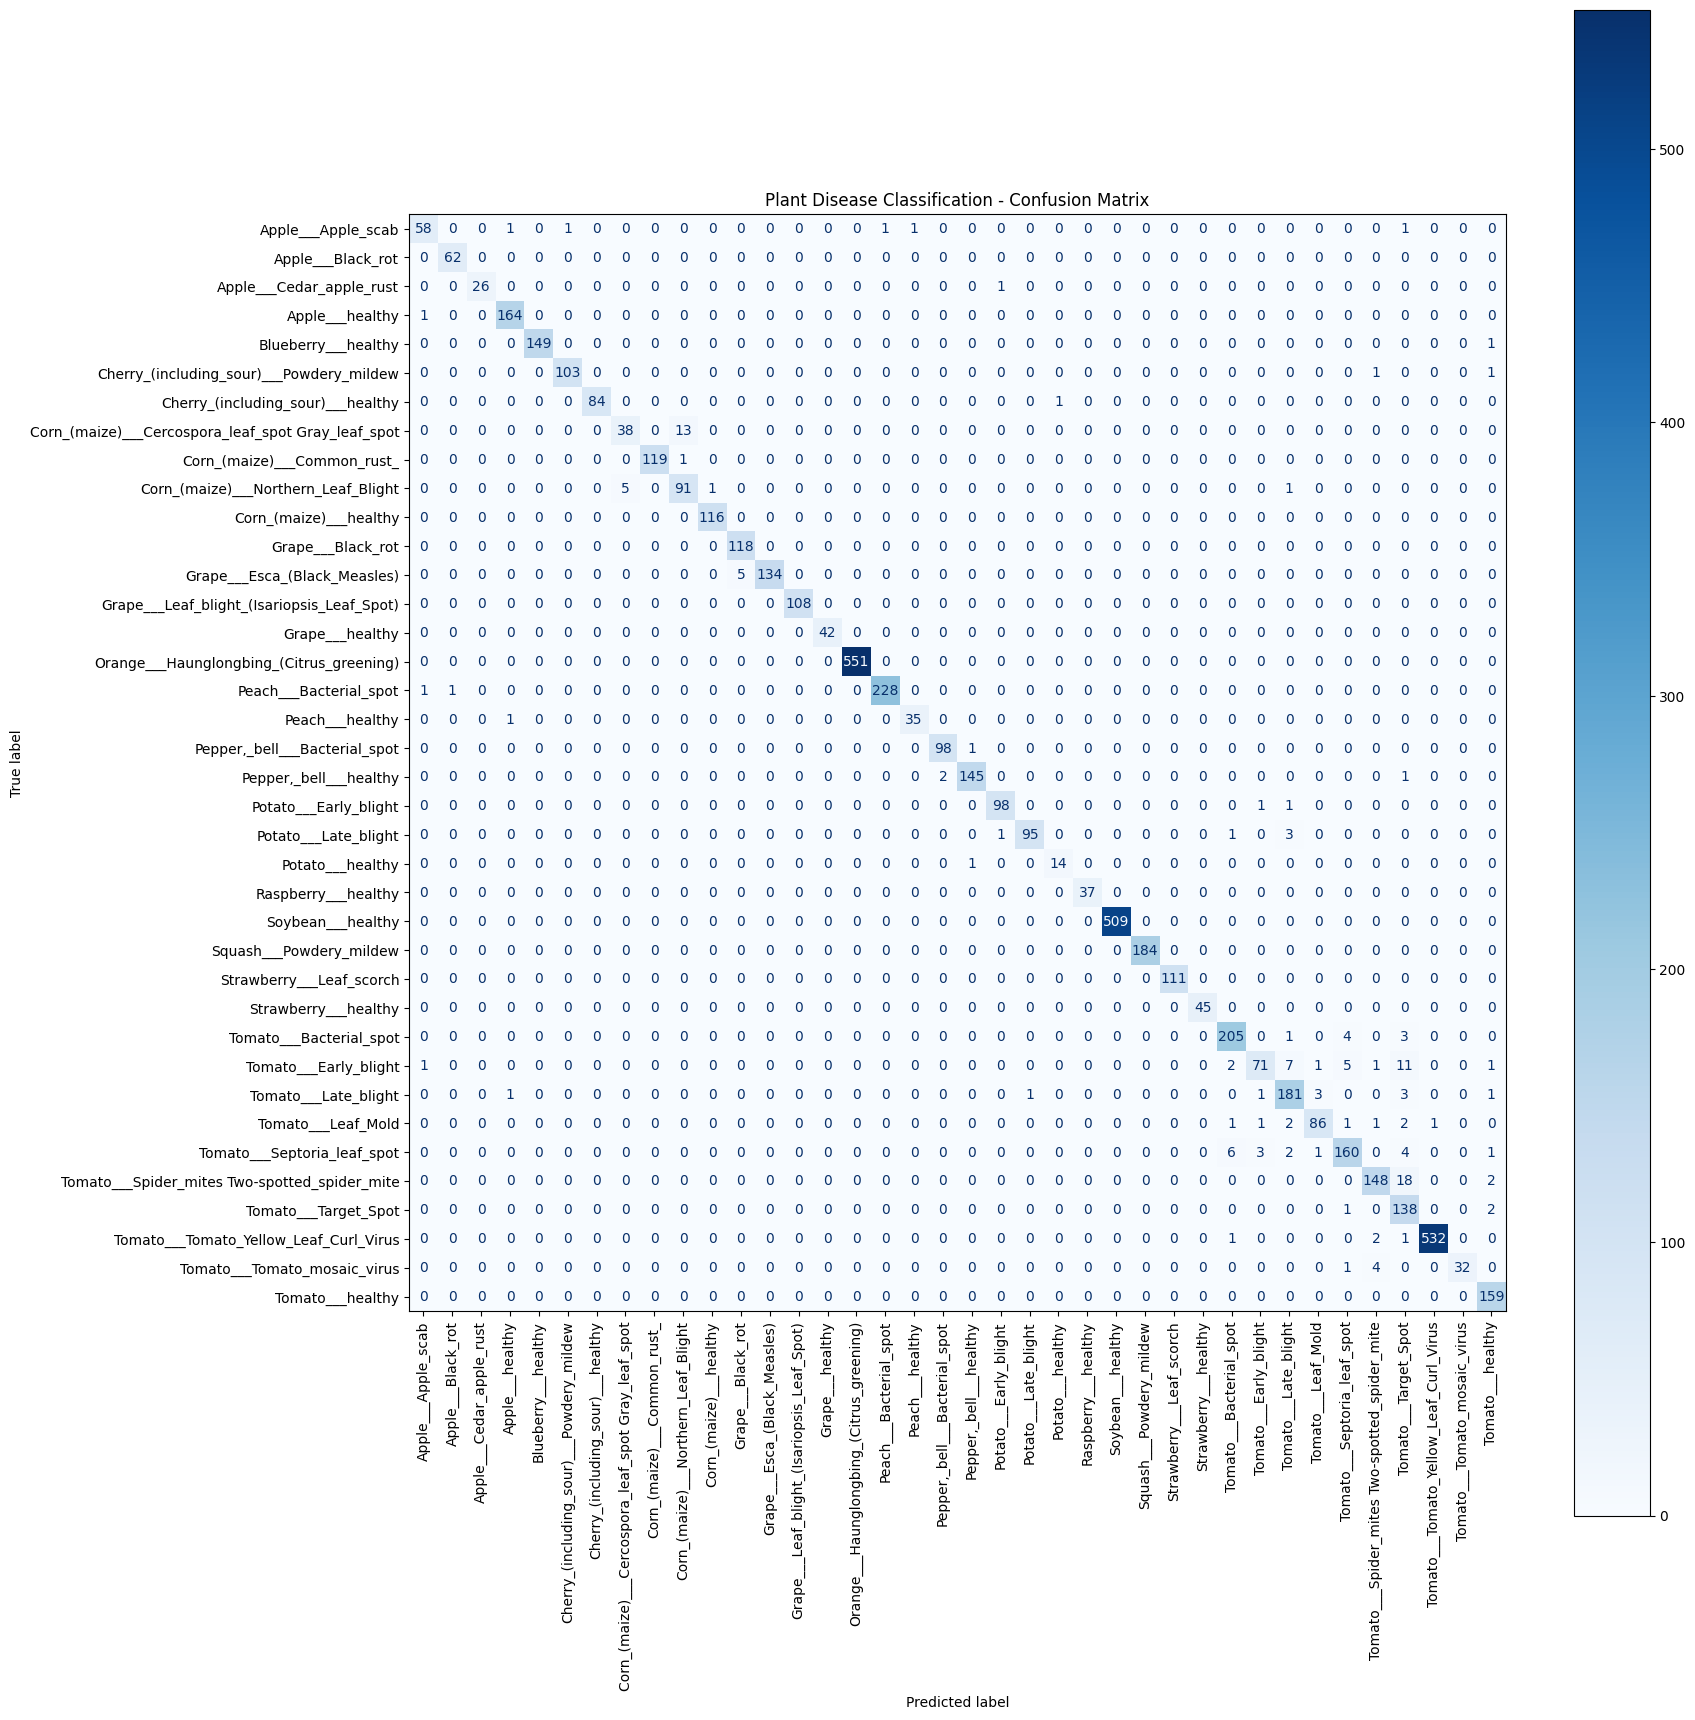

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=range(len(class_names_clean))
)

plt.figure(figsize=(18, 18))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names_clean
)

disp.plot(
    xticks_rotation=90,
    values_format="d",
    ax=plt.gca(),
    cmap="Blues"
)

plt.title("Plant Disease Classification - Confusion Matrix")
plt.tight_layout()
plt.show()

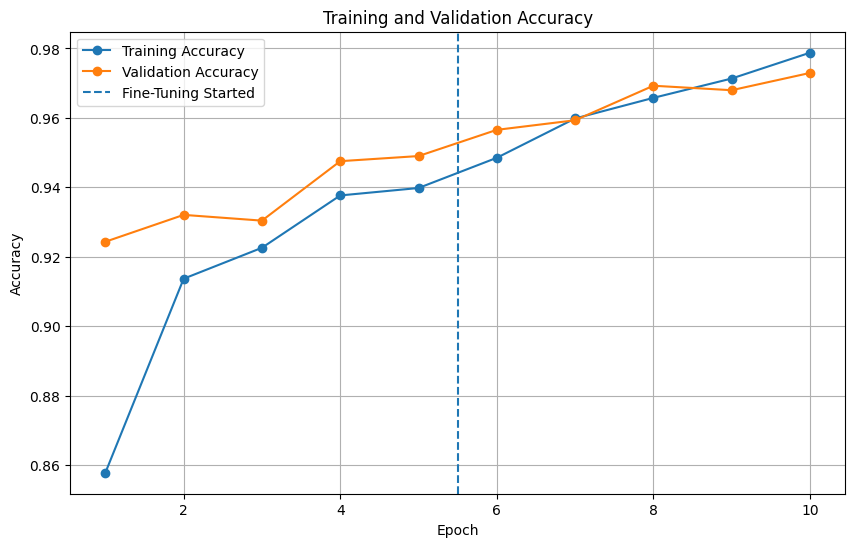

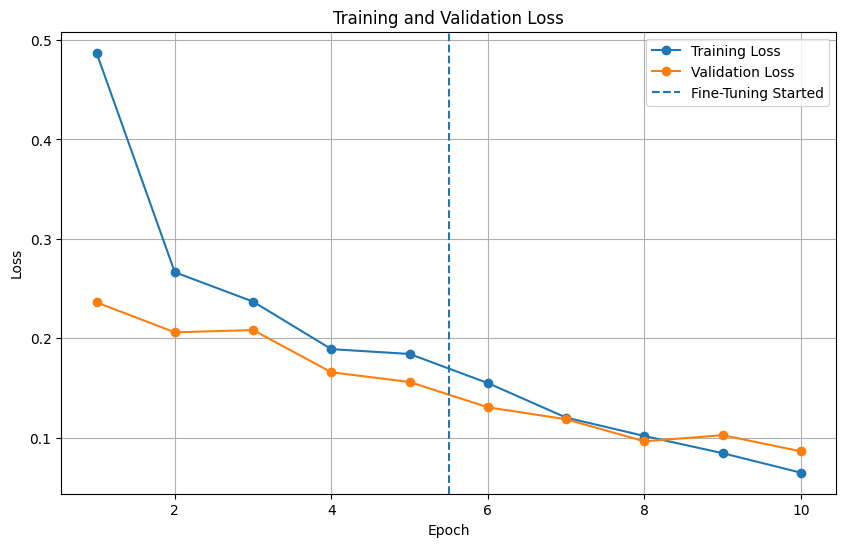

In [ ]:
import matplotlib.pyplot as plt

# Combine Stage 1 and Stage 2 history
acc = history1.history["accuracy"] + history2.history["accuracy"]
val_acc = history1.history["val_accuracy"] + history2.history["val_accuracy"]

loss = history1.history["loss"] + history2.history["loss"]
val_loss = history1.history["val_loss"] + history2.history["val_loss"]

epochs = range(1, len(acc) + 1)

# -----------------------------
# Accuracy Graph
# -----------------------------
plt.figure(figsize=(10, 6))

plt.plot(
    epochs,
    acc,
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    epochs,
    val_acc,
    marker="o",
    label="Validation Accuracy"
)

plt.axvline(
    x=len(history1.history["accuracy"]) + 0.5,
    linestyle="--",
    label="Fine-Tuning Started"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()


# -----------------------------
# Loss Graph
# -----------------------------
plt.figure(figsize=(10, 6))

plt.plot(
    epochs,
    loss,
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs,
    val_loss,
    marker="o",
    label="Validation Loss"
)

plt.axvline(
    x=len(history1.history["loss"]) + 0.5,
    linestyle="--",
    label="Fine-Tuning Started"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
FINAL_MODEL_PATH = "/content/PlantDisease_MobileNetV2_Final.keras"

best_model.save(FINAL_MODEL_PATH)

print("================================")
print("FINAL MODEL SAVED")
print("================================")
print("Path:")
print(FINAL_MODEL_PATH)

print("\n✅ Training pipeline completed.")
print("✅ Model saved successfully.")
print("❌ Ab dobara training ki zarurat nahi hai.")

FINAL MODEL SAVED
Path:
/content/PlantDisease_MobileNetV2_Final.keras

✅ Training pipeline completed.
✅ Model saved successfully.
❌ Ab dobara training ki zarurat nahi hai.


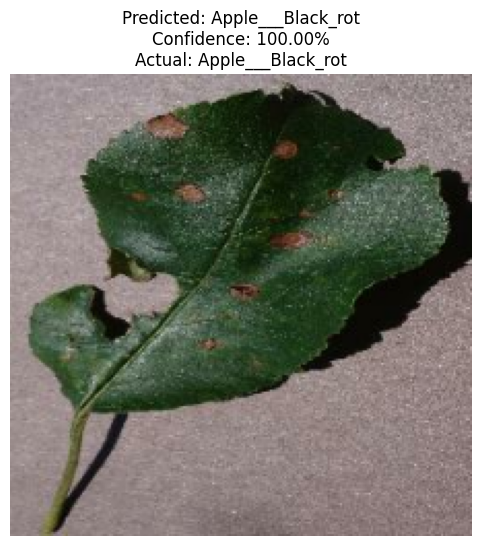

Actual    : Apple___Black_rot
Predicted : Apple___Black_rot
Confidence: 100.00%


In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

FINAL_MODEL_PATH = "/content/PlantDisease_MobileNetV2_Final.keras"

# Load final model
final_model = tf.keras.models.load_model(FINAL_MODEL_PATH)

# Test image select karo
image_path = test_df.iloc[0]["filepath"]
actual_label = test_df.iloc[0]["label"]

# Load image
image = tf.io.read_file(image_path)
image = tf.io.decode_image(
    image,
    channels=3,
    expand_animations=False
)

image = tf.image.resize(image, (224, 224))
image = tf.cast(image, tf.float32)

# Model input
input_image = tf.expand_dims(image, axis=0)

# Prediction
prediction = final_model.predict(
    input_image,
    verbose=0
)

predicted_index = np.argmax(prediction[0])
predicted_label = class_names_clean[predicted_index]
confidence = prediction[0][predicted_index] * 100

# Display
plt.figure(figsize=(6, 6))
plt.imshow(image.numpy().astype("uint8"))
plt.axis("off")
plt.title(
    f"Predicted: {predicted_label}\n"
    f"Confidence: {confidence:.2f}%\n"
    f"Actual: {actual_label}"
)
plt.show()

print("Actual    :", actual_label)
print("Predicted :", predicted_label)
print(f"Confidence: {confidence:.2f}%")

In [ ]:
random_row = test_df.sample(
    n=1,
    random_state=42
).iloc[0]

In [ ]:
from google.colab import files

MODEL_PATH = "/content/PlantDisease_MobileNetV2_Final.keras"

files.download(MODEL_PATH)

print("✅ Final model download started")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✅ Final model download started


In [ ]:
import json
from google.colab import files

CLASS_NAMES_PATH = "/content/class_names.json"

with open(CLASS_NAMES_PATH, "w") as f:
    json.dump(class_names_clean, f, indent=4)

files.download(CLASS_NAMES_PATH)

print("✅ Class names download started")
print("Total classes:", len(class_names_clean))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✅ Class names download started
Total classes: 38


In [ ]:
import os

print(os.path.exists("/content/PlantDisease_MobileNetV2_Final.keras"))
print(os.path.exists("/content/class_names.json"))

True
True


In [ ]:
from google.colab import files

files.download("/content/PlantDisease_MobileNetV2_Final.keras")
files.download("/content/class_names.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os
import random
import shutil
from google.colab import files

SOURCE = "/content/PlantVillage-Dataset/raw/color"
OUTPUT = "/content/plant_test_images"

os.makedirs(OUTPUT, exist_ok=True)

# 10 different classes se 1 image
selected_classes = random.sample(
    class_names_clean,
    min(10, len(class_names_clean))
)

for class_name in selected_classes:
    class_path = os.path.join(SOURCE, class_name)

    images = [
        f for f in os.listdir(class_path)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    if images:
        selected_image = random.choice(images)

        src = os.path.join(class_path, selected_image)

        # Class name filename me preserve hoga
        safe_name = class_name.replace("/", "_") + ".jpg"
        dst = os.path.join(OUTPUT, safe_name)

        shutil.copy2(src, dst)

print("Created test images:")
for f in os.listdir(OUTPUT):
    print(f)

shutil.make_archive(
    "/content/plant_test_images",
    "zip",
    OUTPUT
)

files.download("/content/plant_test_images.zip")

Created test images:
Blueberry___healthy.jpg
Grape___Leaf_blight_(Isariopsis_Leaf_Spot).jpg
Tomato___healthy.jpg
Peach___Bacterial_spot.jpg
Pepper,_bell___healthy.jpg
Grape___Esca_(Black_Measles).jpg
Tomato___Bacterial_spot.jpg
Apple___Black_rot.jpg
Orange___Haunglongbing_(Citrus_greening).jpg
Tomato___Septoria_leaf_spot.jpg


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>